<a href="https://colab.research.google.com/github/cvoidelo/EPB_omicas_aplicadas_ao_cancer_2026/blob/main/EPB_singlecell_rna_seq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introdução à Análise de Dados Ômicos no Câncer: Transcriptômica - single cell RNA-seq

Diferente do *bulk* RNA-seq (que calcula a média de expressão de milhares de células misturadas), o scRNA-seq quantifica o transcriptoma de cada célula individualmente, revelando subpopulações raras, trajetórias de diferenciação e redes complexas de comunicação no microambiente tumoral.

### Módulos do Workshop

| Módulo | Descrição da Etapa | Ferramentas Principais |
|---|---|---|
| **1. Ecossistema e Setup** | Preparação do ambiente, carregamento de dados e formatos. | Seurat, reticulate |
| **2. Controle de Qualidade (QC)** | Filtragem de células mortas, vazias e detecção de *doublets*. | Seurat, scDblFinder |
| **3. Processamento Padrão** | Normalização, redução de dimensionalidade (PCA/UMAP) e clusterização. | Seurat |
| **4. Anotação Celular** | Identificação dos tipos celulares (TME) via modelos de Machine Learning. | CellTypist (Python) |
| **5. Estados Funcionais** | Scoring de assinaturas oncogênicas (Hipóxia, EMT, Ciclo Celular). | CancerSEA-X, Seurat |
| **6. Comunicação Celular** | Inferência de interações ligante-receptor no microambiente. | CellChat |
| **7. Exportação** | Salvamento de resultados e persistência na nuvem. | Google Drive |

---

### Ecossistema: R vs Python
A análise de scRNA-seq é dominada por dois grandes ecossistemas. A escolha depende da escala dos dados e da familiaridade de quem analisa:

*   **R (Seurat / Bioconductor):** Mais abrangente. O **Seurat** é o pacote mais utilizado, fácil manipulação estatística e geração de gráficos. Desempenha bem em datasets de até ~100.000 células.
    *   *Tutorial Oficial:* [Seurat Vignettes](https://satijalab.org/seurat/articles/get_started.html)
*   **Python (Scanpy / scVI):** Focado em *Machine Learning* e escalabilidade. O **Scanpy** consome muito menos memória RAM que o Seurat, ideal para atlas celulares com milhões de células. O **scVI-tools** usa redes neurais profundas (*Deep Learning*) para integração e imputação.
    *   *Livro de Referência Definitivo:* [Single-cell Best Practices (sc-best-practices.org)](https://www.sc-best-practices.org/)

---

### Como os dados de scRNA-seq são armazenados?
A tecnologia mais comum (10x Genomics Chromium) isola células em gotas lipídicas. Após o sequenciamento, o pipeline *CellRanger* gera a matriz de contagens, que pode ser encontrada em três formatos principais em bancos públicos (GEO, ArrayExpress):

1.  **Formato 10x Nativo (Diretório):** Uma pasta contendo três arquivos compactados:
    *   `barcodes.tsv.gz`: O "código de barras" que identifica cada célula (Colunas).
    *   `features.tsv.gz`: O nome/ID de cada gene sequenciado (Linhas).
    *   `matrix.mtx.gz`: A matriz esparsa contendo as contagens (só armazena valores maiores que zero para poupar espaço).
2.  **Formato `.h5ad` (AnnData):** Padrão do Python/Scanpy. É um arquivo HDF5 ultracompacto que guarda a matriz, metadados, PCA e grafos em um único arquivo.
3.  **Formato `.rds` ou `.Robj`:** Padrão do R. Contém o objeto `Seurat` ou `SingleCellExperiment` já montado e pronto para carregar na memória.

## MÓDULO 1: SETUP E CARREGAMENTO DE DADOS

In [1]:
# Instalação rápida dos pacotes necessários
install.packages(c("Seurat", "BiocManager", "remotes", "reticulate", "patchwork", "ggplot2"))
BiocManager::install(c("scDblFinder", "SingleCellExperiment", "ComplexHeatmap", "slingshot"))
remotes::install_github("satijalab/seurat-data")
remotes::install_github("jinworks/CellChat")

library(Seurat)
library(SeuratData)
library(patchwork)
library(scDblFinder)
library(reticulate)
library(CellChat)

# Para baixarmos rapidamente, usaremos o PBMC3k (3.000 células) para todo
# o pipeline base e demonstração de microambiente. Depois isolaremos um grupo
# para simular células do câncer e rodar o CancerSEA-X.
InstallData("pbmc3k")
pbmc <- LoadData("pbmc3k")

cat("Objeto Seurat carregado. Dimensões iniciais:\n")
print(pbmc)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bitops’, ‘dotCall64’, ‘lazyeval’, ‘gtools’, ‘caTools’, ‘plyr’, ‘tensor’, ‘BH’, ‘sitmo’, ‘sp’, ‘spam’, ‘globals’, ‘listenv’, ‘parallelly’, ‘zoo’, ‘crosstalk’, ‘gplots’, ‘reshape2’, ‘gridExtra’, ‘RcppArmadillo’, ‘spatstat.data’, ‘spatstat.univar’, ‘spatstat.random’, ‘spatstat.utils’, ‘spatstat.sparse’, ‘goftest’, ‘abind’, ‘deldir’, ‘polyclip’, ‘FNN’, ‘dqrng’, ‘SeuratObject’, ‘cowplot’, ‘fastDummies’, ‘fitdistrplus’, ‘future’, ‘future.apply’, ‘ggrepel’, ‘ggridges’, ‘ica’, ‘igraph’, ‘irlba’, ‘lmtest’, ‘matrixStats’, ‘pbapply’, ‘plotly’, ‘png’, ‘progressr’, ‘RANN’, ‘RcppAnnoy’, ‘RcppHNSW’, ‘ROCR’, ‘RSpectra’, ‘Rtsne’, ‘scattermore’, ‘sctransform’, ‘spatstat.explore’, ‘spatstat.geom’, ‘uwot’, ‘RcppEigen’, ‘RcppProgress’, ‘RcppThread’, ‘RcppTOML’, ‘here’


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for 

xtable  (1.8-4 -> 1.8-8) [CRAN]
openssl (2.4.2 -> 2.5.0) [CRAN]


Installing 2 packages: xtable, openssl

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpYrzn3z/remotes1de52a57db8d/satijalab-seurat-data-3e51f44/DESCRIPTION’ ... OK
* preparing ‘SeuratData’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
Omitted ‘LazyData’ from DESCRIPTION
* building ‘SeuratData_0.2.2.9002.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)




coda         (NA -> 0.19-4.1  ) [CRAN]
network      (NA -> 1.20.0    ) [CRAN]
statnet.c... (NA -> 4.13.0    ) [CRAN]
urca         (NA -> 1.3-4     ) [CRAN]
timeDate     (NA -> 4052.112  ) [CRAN]
fracdiff     (NA -> 1.5-4     ) [CRAN]
rbibutils    (NA -> 2.4.1     ) [CRAN]
forecast     (NA -> 9.0.2     ) [CRAN]
Deriv        (NA -> 4.3.6     ) [CRAN]
MatrixModels (NA -> 0.5-4     ) [CRAN]
SparseM      (NA -> 1.84-2    ) [CRAN]
doBy         (NA -> 4.7.2     ) [CRAN]
numDeriv     (NA -> 2016.8-1.1) [CRAN]
reformulas   (NA -> 0.4.4     ) [CRAN]
nloptr       (NA -> 2.2.1     ) [CRAN]
minqa        (NA -> 1.2.8     ) [CRAN]
Rdpack       (NA -> 2.6.6     ) [CRAN]
lme4         (NA -> 2.1-0     ) [CRAN]
quantreg     (NA -> 6.1       ) [CRAN]
pbkrtest     (NA -> 0.5.5     ) [CRAN]
Formula      (NA -> 1.2-6     ) [CRAN]
carData      (NA -> 3.0-6     ) [CRAN]
car          (NA -> 3.1-5     ) [CRAN]
corrplot     (NA -> 0.95      ) [CRAN]
sna          (NA -> 2.8       ) [CRAN]
rstatix      (NA -> 1.1.0

Skipping 4 packages not available: Biobase, BiocNeighbors, BiocGenerics, ComplexHeatmap

Installing 38 packages: coda, network, statnet.common, urca, timeDate, fracdiff, rbibutils, forecast, Deriv, MatrixModels, SparseM, doBy, numDeriv, reformulas, nloptr, minqa, Rdpack, lme4, quantreg, pbkrtest, Formula, carData, car, corrplot, sna, rstatix, polynom, ggsignif, ggsci, gridBase, rngtools, registry, collapse, ggnetwork, ggpubr, svglite, ggalluvial, NMF

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpYrzn3z/remotes1de575682e9c/jinworks-CellChat-75253cd/DESCRIPTION’ ... OK
* preparing ‘CellChat’:
* checking DESCRIPTION meta-information ... OK
* cleaning src
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* building ‘CellChat_2.2.0.9001.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.


Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuanti

Objeto Seurat carregado. Dimensões iniciais:
An object of class Seurat 
13714 features across 2700 samples within 1 assay 
Active assay: RNA (13714 features, 0 variable features)
 2 layers present: counts, data


---
## Módulo 2: Controle de Qualidade (QC) e Remoção de Doublets

### Critérios Padrões de Filtragem
1. **`min.cells = 3` e `min.features = 200`:** Genes expressos em menos de 3 células são ruído. Células com menos de 200 genes detectados são fragmentos ou gotas vazias. (Isso já foi aplicado na criação do objeto).
2. **`percent.mt`:** Células em sofrimento/apoptose rompem a membrana plasmática, vazando RNA citoplasmático, mas retendo RNA mitocondrial. Filtramos células com **> 5%** de expressão mitocondrial para manter apenas células saudáveis e transcricionalmente ativas.

### Detecção de Doublets (Células Duplas)
Um *doublet* ocorre quando duas células entram na mesma gota no equipamento, gerando um perfil quimérico aberrante. Métodos computacionais simulam doublets artificiais combinando células aleatórias e verificam se alguma célula real do dataset se parece com essas simulações.
* **Scrublet (Python):** Rápido, roda via k-NN, mas otimizado apenas para amostras individuais.
* **DoubletFinder (R):** Muito popular no ecossistema Seurat, usa proporções artificiais baseadas em PCA.
* **scDblFinder (R/Bioconductor):** O estado-da-arte atual. Extremamente rápido e iterativo, ele classifica doublets de forma mais precisa, agrupando células antes da simulação para evitar falsos positivos em transições de linhagem. É o que usaremos aqui.

Warning message:
“Layer ‘scale.data’ is empty”
Creating ~2111 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 208 cells excluded from training.

iter=1, 183 cells excluded from training.

iter=2, 136 cells excluded from training.

Threshold found:0.396

116 (4.4%) doublets called



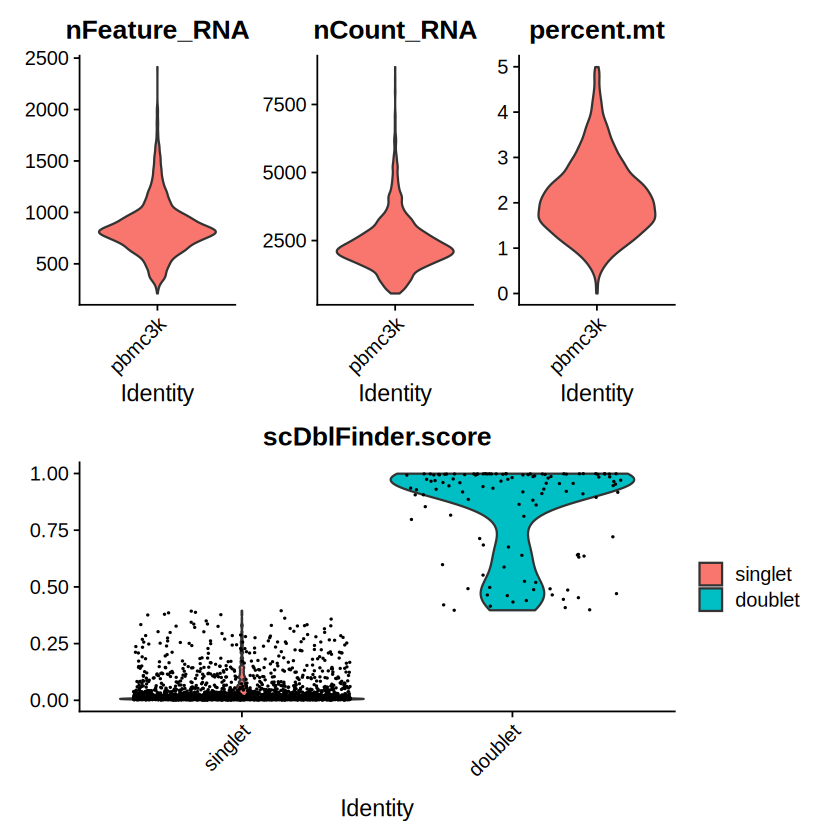

In [2]:
# MÓDULO 2: QC E DOUBLETS

# 1. Cálculo da porcentagem mitocondrial
pbmc[["percent.mt"]] <- PercentageFeatureSet(pbmc, pattern = "^MT-")

# 2. Filtragem de QC (mantém células de alta qualidade)
pbmc <- subset(pbmc, subset = nFeature_RNA > 200 & nFeature_RNA < 2500 & percent.mt < 5)

# 3. Execução do scDblFinder (Convertendo temporariamente para SingleCellExperiment)
sce <- as.SingleCellExperiment(pbmc)
set.seed(123)
sce <- scDblFinder(sce)

# Trazendo o resultado de volta para o Seurat
pbmc$scDblFinder.class <- sce$scDblFinder.class
pbmc$scDblFinder.score <- sce$scDblFinder.score

# 4. Gráfico do QC e Doublets
p1 <- VlnPlot(pbmc, features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), ncol = 3, pt.size = 0)
p2 <- VlnPlot(pbmc, features = "scDblFinder.score", group.by = "scDblFinder.class")

p1 / p2

---
### O que os gráficos de QC representam?
* **Violin Plots Superiores:** Mostram a distribuição do número de genes (`nFeature_RNA`), total de moléculas (`nCount_RNA`) e o lixo mitocondrial (`percent.mt`). O corte abrupto em 5% no último gráfico comprova que o filtro funcionou.
* **Violin Plot Inferior (Doublets):** Mostra a separação clara do escore de simulação. Células à direita (`doublet`) têm alta similaridade com hibridizações artificiais e serão removidas da análise para não criar "clusters fantasmas".

In [3]:
# Remove os doublets identificados
pbmc <- subset(pbmc, subset = scDblFinder.class == "singlet")
cat("Número de células saudáveis únicas restantes:", ncol(pbmc), "\n")

Número de células saudáveis únicas restantes: 2522 


## MÓDULO 3: PROCESSAMENTO PADRÃO DO SEURAT

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  MALAT1, LTB, IL32, IL7R, CD2, B2M, CD27, ACAP1, STK17A, CD247 
	   CTSW, RARRES3, GIMAP5, AQP3, CCL5, SELL, MAL, GZMA, CST7, ITM2A 
	   MYC, GIMAP7, BEX2, LDLRAP1, HOPX, ETS1, PNISR, GZMK, ZAP70, MZT2A 
Negative:  CST3, TYROBP, LST1, AIF1, FTL, LYZ, FTH1, FCN1, TYMP, S100A9 
	   FCER1G, CFD, LGALS1, CTSS, LGALS2, SERPINA1, S100A8, IFITM3, SPI1, CFP 
	   PSAP, IFI30, SAT1, COTL1, S100A11, NPC2, GRN, LGALS3, GSTP1, PYCARD 
PC_ 2 
Positive:  NKG7, GZMB, CST7, PRF1, GZMA, FGFBP2, GNLY, CTSW, B2M, SPON2 
	   CCL4, GZMH, FCGR3A, CCL5, XCL2, CD247, CLIC3, AKR1C3, TTC38, HOPX 
	   SRGN, APMAP, CTSC, IGFBP7, RARRES3, XCL1, S100A4, ID2, TPST2, RHOC 
Negative:  CD79A, TCL1A, HLA-DQA1, HLA-DRA, HLA-DQB1, LINC00926, CD79B, HLA-DRB1, CD74, HLA-DMA 
	   LTB, HLA-DQA2, HLA-DPB1, HLA-DRB5, HLA-DMB, HLA-DPA1, HVCN1, FCRLA, BLNK, P2RX5 
	   IGLL5, IRF8, QRSL1, SWAP70, ARHGAP24, SMIM

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2522
Number of edges: 91845

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8773
Number of communities: 9
Elapsed time: 0 seconds


20:22:14 UMAP embedding parameters a = 0.9922 b = 1.112

20:22:14 Read 2522 rows and found 10 numeric columns

20:22:14 Using Annoy for neighbor search, n_neighbors = 30

20:22:14 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

20:22:15 Writing NN index file to temp file /tmp/RtmpYrzn3z/file1de571121d72

20:22:15 Searching Annoy index using 1 thread, search_k = 3000

20:22:15 Annoy recall = 100%

20:22:16 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

20:22:19 Initializing from normalized Laplacian + noise (using RSpectra)

20:22:19 Commencing optimization for 500 epochs, with 100382 positive edges

20:22:19 Using rng type: pcg

20:22:23 Optimization finished



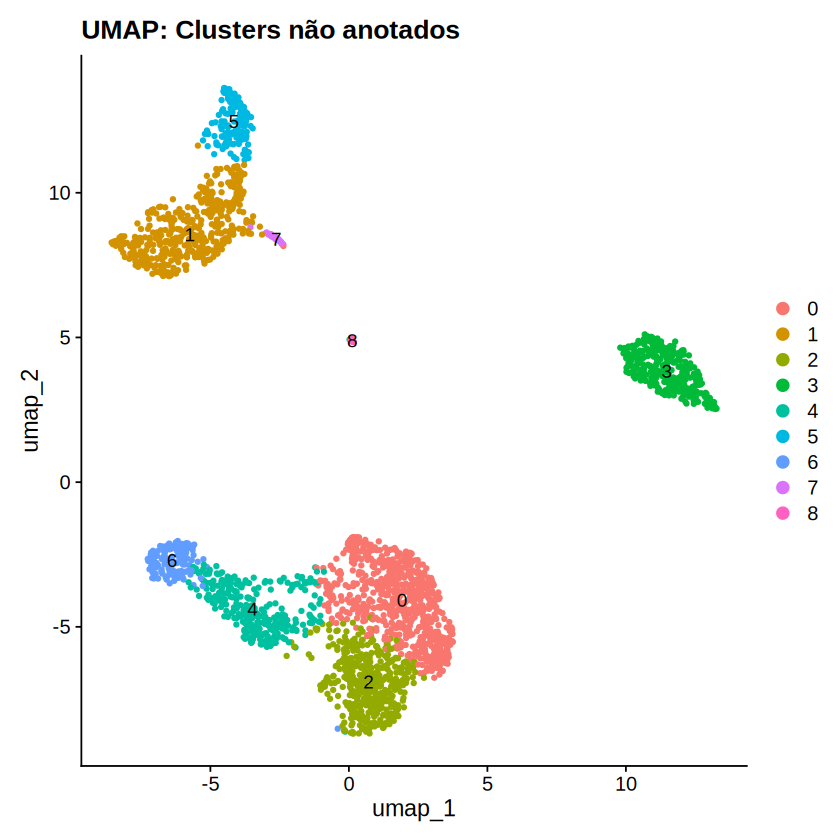

In [4]:
# 1. Normalização Logarítmica (LogNormalize)
pbmc <- NormalizeData(pbmc, normalization.method = "LogNormalize", scale.factor = 10000)

# 2. Seleção de Features Altamente Variáveis (Top 2000 genes)
pbmc <- FindVariableFeatures(pbmc, selection.method = "vst", nfeatures = 2000)

# 3. Scaling (Centraliza a média em 0 e variância em 1 para a PCA não ser enviesada por genes hiper-expressos)
pbmc <- ScaleData(pbmc)

# 4. Redução de Dimensionalidade Linear (PCA)
pbmc <- RunPCA(pbmc, features = VariableFeatures(object = pbmc))

# 5. Clusterização baseada em Grafos (K-Nearest Neighbors e Louvain)
pbmc <- FindNeighbors(pbmc, dims = 1:10)
pbmc <- FindClusters(pbmc, resolution = 0.5)

# 6. Redução de Dimensionalidade Não-Linear (UMAP)
pbmc <- RunUMAP(pbmc, dims = 1:10)

DimPlot(pbmc, reduction = "umap", label = TRUE, pt.size = 1) +
  ggtitle("UMAP: Clusters não anotados")

---
## Módulo 4: Anotação Celular Automática com CellTypist

No *bulk* RNA-seq, tínhamos o tecido todo misturado. Aqui, o UMAP gerou agrupamentos, mas o computador não sabe quem é quem (Cluster 0, 1, 2...).

O **CellTypist** é uma ferramenta ultrarrápida em Python que utiliza Regressão Logística baseada em um modelo treinado com milhões de células anotadas para classificar a identidade das nossas. Ele possui diferentes níveis de resolução anatômica:
* **Modelo `Immune_All_High`:** Foca em grandes linhagens de alto nível (Ex: *T cells*, *B cells*, *Macrophages*). É mais seguro e generalista.
* **Modelo `Immune_All_Low`:** Foca na hierarquia profunda de baixo nível (Ex: *Memory CD4+ T cells*, *Gamma-delta T cells*, *DC1*). Mais detalhado, porém sujeito a mais falsos positivos se a célula estiver em transição.

> Como o Colab está em R, usaremos a biblioteca `reticulate` para instanciar o Python silenciosamente por trás, rodar o CellTypist na matriz do Seurat e trazer as anotações prontas de volta para o R!

In [24]:
# MÓDULO 4: ANOTAÇÃO CELULAR AUTOMÁTICA COM CELLTYPIST (INTEGRAÇÃO R-PYTHON)

# 1. Instalação e atualização dos pacotes Python no ambiente do Colab
system("python3 -m pip install scanpy celltypist --break-system-packages", ignore.stdout = TRUE, ignore.stderr = TRUE)

library(reticulate)

# 2. Preparação e exportação dos dados do Seurat para o Python
# Extraímos a matriz de contagens para a classificação algorítmica
matriz_counts <- GetAssayData(pbmc, layer = "counts")
celulas_nomes <- colnames(pbmc)
genes_nomes   <- rownames(pbmc)

# Transposição para o formato padrão do Scanpy/AnnData (células nas linhas, genes nas colunas)
matriz_export <- as.matrix(t(matriz_counts))

# Transferência dos objetos para o ambiente Python (acessíveis via dicionário 'r')
py$matriz_export <- matriz_export
py$celulas_nomes <- celulas_nomes
py$genes_nomes   <- genes_nomes

# 3. Execução do pipeline computacional em Python
py_run_string("
import pandas as pd
import pandas.api.types

# Aplicação de patch de compatibilidade estrutural para ambientes de nuvem
if not hasattr(pd.api.types, 'is_interval'):
    pd.api.types.is_interval = lambda x: False

import anndata as ad
import scanpy as sc
import celltypist
from celltypist import models

# Criação do objeto AnnData com alinhamento preciso de células e genes
adata = ad.AnnData(
    X=r.matriz_export,
    obs=pd.DataFrame(index=r.celulas_nomes),
    var=pd.DataFrame(index=r.genes_nomes)
)

# Garante que a matriz de dados exportada seja gravável (corrige o bloqueio de leitura do R)
adata.X = adata.X.copy()

# Pré-processamento padrão exigido pelo modelo (normalização 10k e transformação logarítmica)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Download e carregamento dos modelos de referência do sistema imune
models.download_models(force_update=False)

# Predição de Alta Resolução (Low: Subtipos celulares detalhados)
predictions_low = celltypist.annotate(adata, model='Immune_All_Low.pkl', majority_voting=True)
anotacao_low = predictions_low.predicted_labels['majority_voting'].tolist()

# Predição de Baixa Resolução (High: Grandes linhagens imunológicas)
predictions_high = celltypist.annotate(adata, model='Immune_All_High.pkl', majority_voting=True)
anotacao_high = predictions_high.predicted_labels['majority_voting'].tolist()
")

# 4. Importação dos resultados e integração ao objeto Seurat
pbmc$CellTypist_Low  <- unlist(py$anotacao_low)
pbmc$CellTypist_High <- unlist(py$anotacao_high)

cat("✅ Anotação celular via CellTypist concluída com sucesso!\n")

✅ Anotação celular via CellTypist concluída com sucesso!


In [25]:
library(dplyr)

# Frequência e porcentagem - Nível High
tabela_high <- pbmc@meta.data %>%
  count(CellTypist_High, name = "N_Celulas") %>%
  mutate(Porcentagem = round((N_Celulas / sum(N_Celulas)) * 100, 2)) %>%
  arrange(desc(N_Celulas))

# Frequência e porcentagem - Nível Low
tabela_low <- pbmc@meta.data %>%
  count(CellTypist_Low, name = "N_Celulas") %>%
  mutate(Porcentagem = round((N_Celulas / sum(N_Celulas)) * 100, 2)) %>%
  arrange(desc(N_Celulas))

# Exibição limpa no console
cat("=== NÍVEL HIGH ===\n")
print(as.data.frame(tabela_high))

cat("\n=== NÍVEL LOW ===\n")
print(as.data.frame(tabela_low))

=== NÍVEL HIGH ===
           CellTypist_High N_Celulas Porcentagem
1                  T cells      1404       55.67
2                Monocytes       596       23.63
3                  B cells       327       12.97
4                      ILC       141        5.59
5                       DC        39        1.55
6 Megakaryocytes/platelets        15        0.59

=== NÍVEL LOW ===
                CellTypist_Low N_Celulas Porcentagem
1     Tcm/Naive helper T cells       986       39.10
2          Classical monocytes       440       17.45
3                      B cells       327       12.97
4      Non-classical monocytes       156        6.19
5               CD16+ NK cells       141        5.59
6                     NK cells       108        4.28
7  Tem/Effector helper T cells        94        3.73
8                   MAIT cells        85        3.37
9  Tcm/Naive cytotoxic T cells        77        3.05
10   Tem/Trm cytotoxic T cells        54        2.14
11                          DC      

---
## Módulo 5: Estados Funcionais Oncogênicos (CancerSEA-X)

Para validar a abordagem em células tumorais, vamos extrair um subset simulado e assumir que são células cancerosas.
O **CancerSEA-X** é um atlas que mapeia assinaturas genéticas de **estados funcionais do câncer** a nível de single-cell.

Vamos baixar a tabela de assinaturas direto do GitHub e aplicar a função `AddModuleScore` do Seurat. Ela avalia a expressão conjunta do painel de genes de cada assinatura, descontando a expressão basal de genes controle para evitar vieses metabólicos.

✅ Scores funcionais calculados e plotados com sucesso!


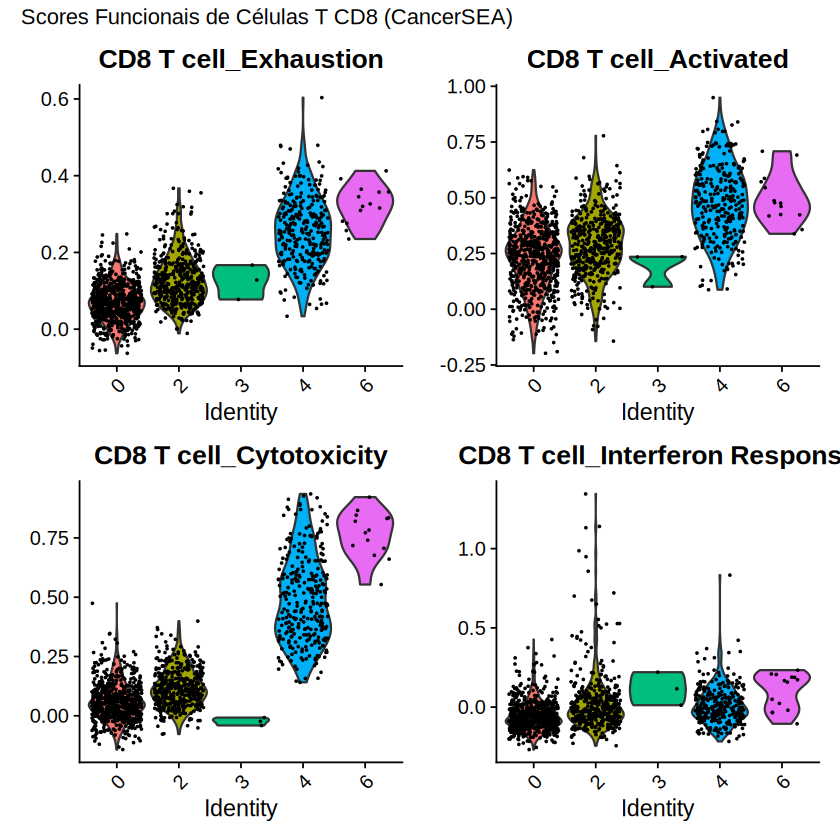

In [30]:
# MÓDULO 5: SCORING DE ESTADOS FUNCIONAIS (CÉLULAS T CD8)


# 1. Seleciona o cluster de Células T com base na anotação do CellTypist
seurat_cancer <- subset(pbmc, subset = CellTypist_High == "T cells")

# 2. Download da tabela de assinaturas do repositório (link corrigido para raw)
url_cancersea <- "https://raw.githubusercontent.com/cvoidelo/EPB_omicas_aplicadas_ao_cancer_2026/main/notebooks/CD8%20T%20cell.tsv"
cancer_sigs <- read.delim(url_cancersea, header = TRUE, sep = "\t")

# Processamento das assinaturas genéticas por estado funcional
lista_assinaturas <- split(cancer_sigs$Signature, cancer_sigs$Cell.State)
lista_assinaturas <- lapply(lista_assinaturas, function(x) trimws(unique(unlist(strsplit(x, ",")))))

# 3. Seleção dos estados mais prováveis e informativos em células T no câncer
estados_interesse <- c(
  "CD8 T cell_Exhaustion",
  "CD8 T cell_Activated",
  "CD8 T cell_Cytotoxicity",
  "CD8 T cell_Interferon Response"
)

# Filtra apenas os estados que existem na lista baixada
estados_interesse <- intersect(estados_interesse, names(lista_assinaturas))
lista_filtro <- lista_assinaturas[estados_interesse]

# 4. Controle de qualidade: Mantém apenas genes presentes no objeto Seurat
genes_do_objeto <- rownames(seurat_cancer)
lista_filtro <- lapply(lista_filtro, function(genes) {
  intersect(genes, genes_do_objeto)
})

# Remove assinaturas vazias e valida os estados finais
tamanhos <- sapply(lista_filtro, length)
lista_filtro <- lista_filtro[tamanhos > 0]
estados_validos <- names(lista_filtro)

# 5. Cálculo do escore funcional via AddModuleScore
if (length(lista_filtro) > 0) {
  seurat_cancer <- AddModuleScore(
    object = seurat_cancer,
    features = lista_filtro,
    name = "T_Cell_Score"
  )

  # Renomeia dinamicamente as colunas no metadado para os nomes dos estados
  col_inicio <- ncol(seurat_cancer@meta.data) - length(estados_validos) + 1
  col_fim <- ncol(seurat_cancer@meta.data)
  colnames(seurat_cancer@meta.data)[col_inicio:col_fim] <- estados_validos

  # 6. Visualização da distribuição dos estados funcionais nas células T
  print(
    VlnPlot(seurat_cancer, features = estados_validos, pt.size = 0.2, ncol = 2) +
      patchwork::plot_annotation(title = "Scores Funcionais de Células T CD8 (CancerSEA)")
  )

  cat("✅ Scores funcionais calculados e plotados com sucesso!\n")
} else {
  cat("⚠️ Nenhuma das assinaturas possui genes expressos neste objeto de células.\n")
}

---
## Módulo 6: Inferência de Comunicação Celular (CellChat)

Já sabemos "quem são" as células (Módulo 4) e o "estado" em que estão (Módulo 5). A fronteira final é descobrir **como elas conversam**. O `CellChat` cruza a expressão gênica das células com um banco de dados de ligantes e receptores reais.

Se a Célula A expressa a citocina *CCL2* (ligante) e a Célula B expressa *CCR2* (receptor), o CellChat calcula a probabilidade matemática (lei de ação das massas) de que A está enviando um sinal de recrutamento para B.

> **Adaptação para Aula:** O CellChat comparativo exige 2 grupos (ex: Saudável vs Tratado). Como temos apenas 1 grupo no PBMC3k, vamos dividi-lo artificialmente em `Controle` e `Tratado` com base em amostragem aleatória apenas para demonstrar o código comparativo em funcionamento.

[1] "Create a CellChat object from a Seurat object"
The `meta.data` slot in the Seurat object is used as cell meta information 


Warning message in createCellChat(object = seurat_subset, group.by = "ident", assay = "RNA"):
“The 'meta' data does not have a column named `samples`. We now add this column and all cells are assumed to belong to `sample1`! 
”


Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  T_cells, B_cells, Monocytes, ILC, DC, Megakaryocytes_platelets 
The number of highly variable ligand-receptor pairs used for signaling inference is 250 
triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2026-11-02 21:11:42.030074]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2026-11-02 21:11:47.328729]"
The cell-cell communication related with the following cell groups are excluded due to the few number of cells:  Megakaryocytes_platelets ! 	25.7% interactions are removed!
[1] "Create a CellChat object from a Seurat object"
The `meta.data` slot in the Seurat object is used as cell meta information 


Warning message in createCellChat(object = seurat_subset, group.by = "ident", assay = "RNA"):
“The 'meta' data does not have a column named `samples`. We now add this column and all cells are assumed to belong to `sample1`! 
”


Set cell identities for the new CellChat object 
The cell groups used for CellChat analysis are  T_cells, B_cells, Monocytes, ILC, DC, Megakaryocytes_platelets 
The number of highly variable ligand-receptor pairs used for signaling inference is 236 
triMean is used for calculating the average gene expression per cell group. 
[1] ">>> Run CellChat on sc/snRNA-seq data <<< [2026-11-02 21:11:50.822058]"
[1] ">>> CellChat inference is done. Parameter values are stored in `object@options$parameter` <<< [2026-11-02 21:11:54.935169]"
The cell-cell communication related with the following cell groups are excluded due to the few number of cells:  Megakaryocytes_platelets ! 	20.1% interactions are removed!


Merge the following slots: 'data.signaling','images','net', 'netP','meta', 'idents', 'var.features' , 'DB', and 'LR'.



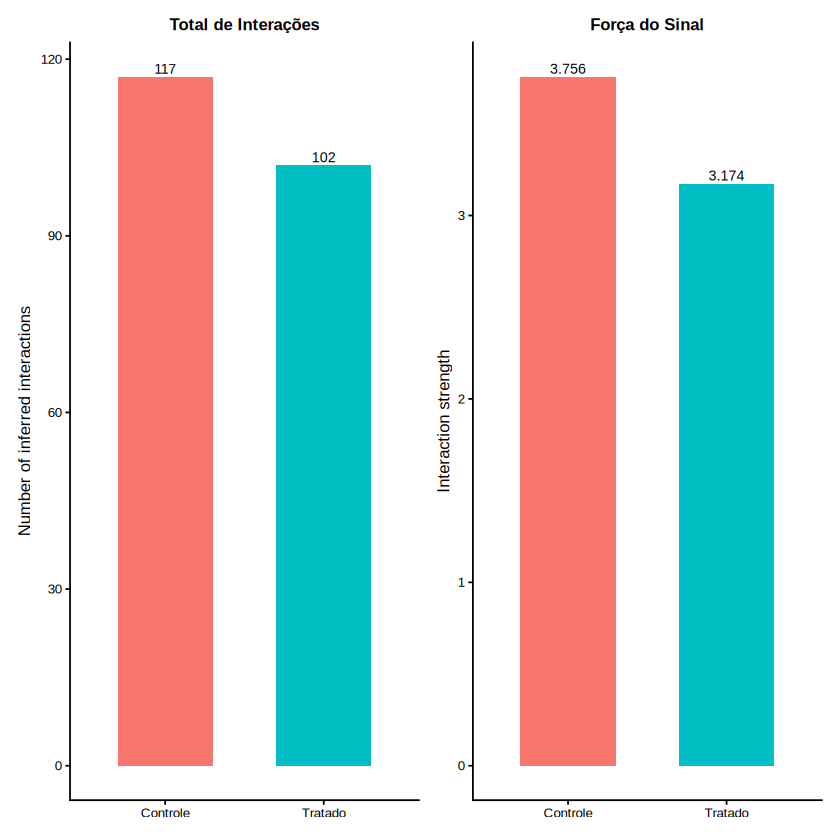

In [33]:
# MÓDULO 6: CELLCHAT COMPARATIVO


# 1. Criando divisão simulada (Controle vs Tratado) no dataset original
set.seed(42)
pbmc$condicao <- sample(c("Controle", "Tratado"), ncol(pbmc), replace = TRUE)
pbmc$amostra_id <- paste0("Sample_", pbmc$condicao)

# 2. Fixando a identidade celular usando a anotação HIGH do CellTypist
Idents(pbmc) <- "CellTypist_High"
pbmc$CellTypist_High <- gsub("[/ ]", "_", pbmc$CellTypist_High)
Idents(pbmc) <- pbmc$CellTypist_High

# Função wrapper para rodar o CellChat de forma limpa e rápida
rodar_cellchat <- function(seurat_subset) {
  # Instancia
  cc <- createCellChat(object = seurat_subset, group.by = "ident", assay = "RNA")
  cc@DB <- CellChatDB.human # Banco de dados humano

  # Processamento (TriMean corta ruído e dropouts)
  cc <- subsetData(cc)

  # ⚠️ ALTERAÇÃO AQUI: Mudamos para do.fast = FALSE para evitar a exigência do pacote presto
  cc <- identifyOverExpressedGenes(cc, do.fast = FALSE)
  cc <- identifyOverExpressedInteractions(cc)

  # Inferência
  cc <- computeCommunProb(cc, type = "triMean", nboot = 20)
  cc <- filterCommunication(cc, min.cells = 10)
  cc <- computeCommunProbPathway(cc)
  cc <- aggregateNet(cc)

  return(cc)
}

# Roda o CellChat para os dois grupos separados
cc_controle <- rodar_cellchat(subset(pbmc, condicao == "Controle"))
cc_tratado  <- rodar_cellchat(subset(pbmc, condicao == "Tratado"))

# Mescla os dois objetos para análise comparativa diferencial
cc_merge <- mergeCellChat(list(Controle = cc_controle, Tratado = cc_tratado), add.names = c("Controle", "Tratado"))

# 3. Gráfico de Comparação Global (Volume de conversas e Força)
p_volume <- compareInteractions(cc_merge, show.legend = FALSE, group = c(1, 2)) + ggtitle("Total de Interações")
p_forca <- compareInteractions(cc_merge, show.legend = FALSE, group = c(1, 2), measure = "weight") + ggtitle("Força do Sinal")

p_volume + p_forca

---
### O que o Bubble Plot do CellChat representa?

Abaixo plotaremos um gráfico de bolhas focando nas vias alteradas.
* **Linhas (Eixo Y):** Os pares Ligante-Receptor.
* **Colunas (Eixo X):** A rota da mensagem (Quem envia -> Quem recebe).
* **Cor da Bolha:** A intensidade da comunicação (Probabilidade).
* **Tamanho da Bolha:** A significância estatística (p-valor).
Bolhas que estão ausentes ou claras no *Controle* mas explodem em cor no *Tratado* são interações diretamente induzidas pela condição!

Comparing communications on a merged object 




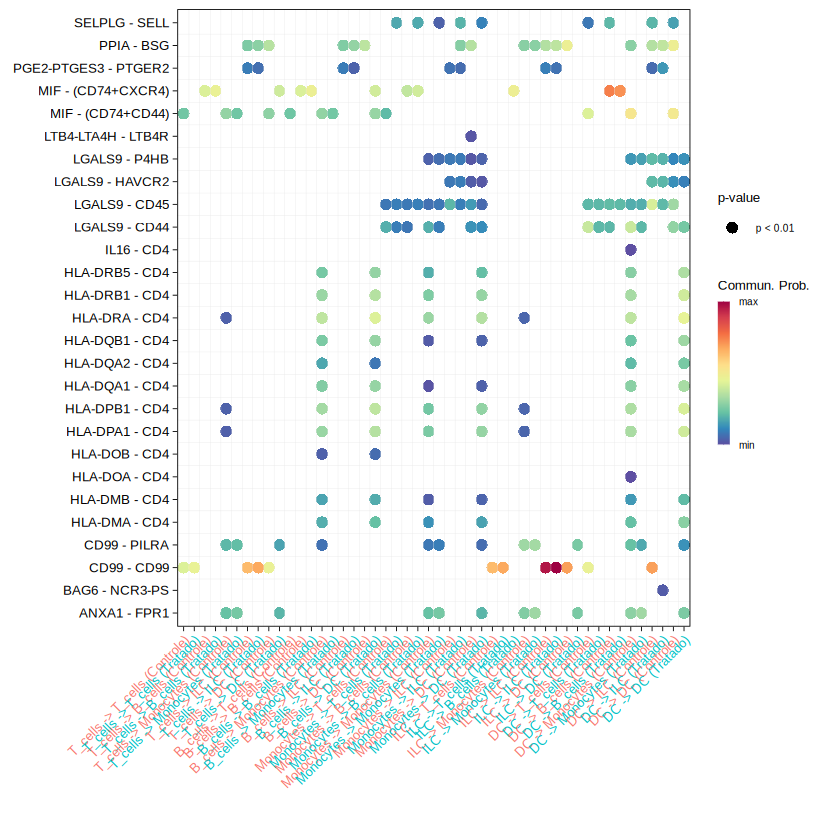

In [46]:
netVisual_bubble(
  cc_merge,
  comparison = c(1, 2),
  angle.x = 45,
  remove.isolate = TRUE
)

Comparing communications on a merged object 




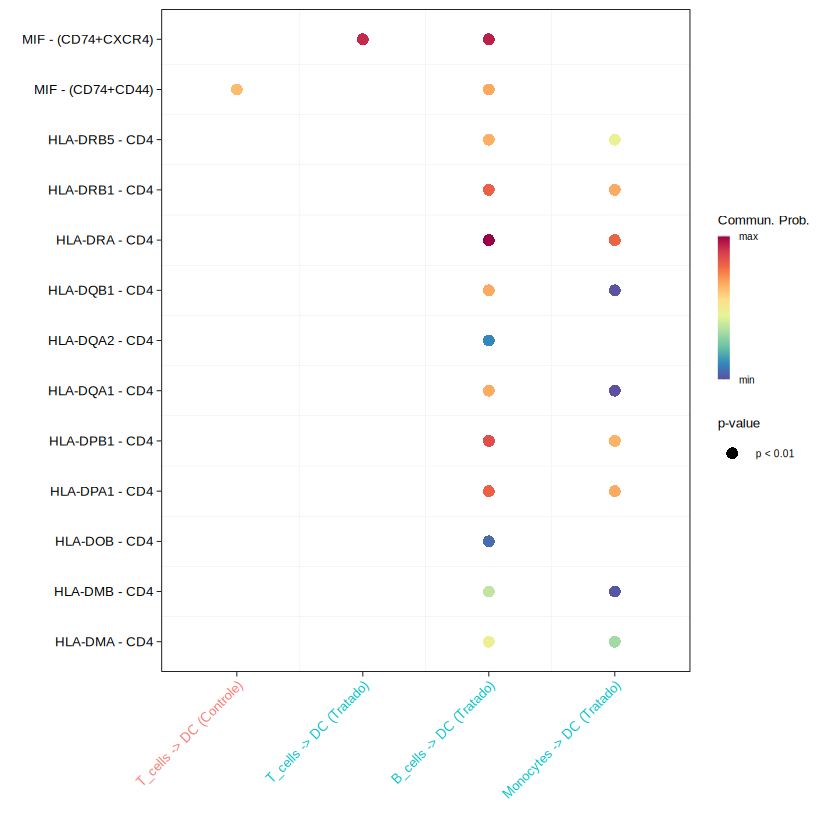

In [42]:
# BUBBLE PLOT COMPARATIVO (INTERAÇÕES LIGANTE-RECEPTOR)

# Seleciona algumas vias de sinalização ativas para comparar entre os grupos
vias_interesse <- c("MIF", "MHC-II")

# Gera o gráfico de bolhas comparativo entre os objetos mesclados (Controle vs Tratado)
netVisual_bubble(
  cc_merge,
  sources.use = c(1, 2, 3),        # Índices ou nomes dos grupos emissores
  targets.use = c(4, 5, 6),        # Índices ou nomes dos grupos receptores
  signaling = vias_interesse,
  comparison = c(1, 2),            # Compara o grupo 1 (Controle) com o grupo 2 (Tratado)
  angle.x = 45,
  remove.isolate = TRUE
)

---
### Comparação de Vias de Sinalização (Information Flow)

Nem toda via de comunicação é alterada da mesma forma. O gráfico de **Information Flow (rankNet)** soma a probabilidade de todas as interações dentro de uma via específica e compara o peso absoluto entre os dois grupos.

* **Barras Vermelhas (Tratado) vs Azul (Controle):** Mostram a dominância de uma via. Se a barra vermelha é muito maior na via "CCL", significa que o tratamento ativou fortemente o recrutamento de quimiocinas. Vias que só possuem barra de uma cor são exclusivas daquela condição.

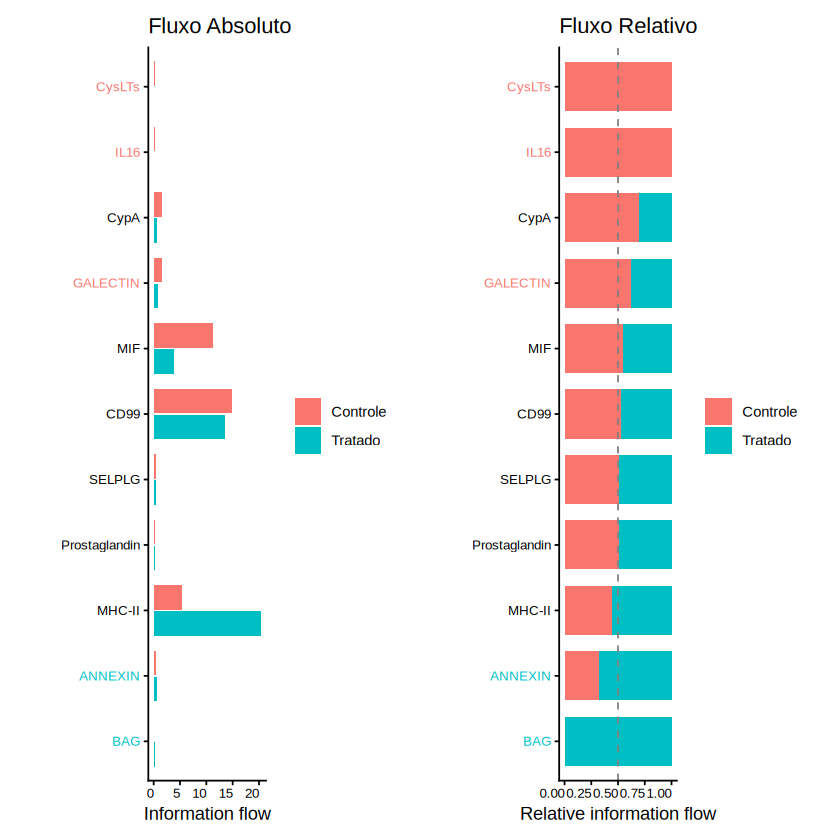

In [43]:
# 4. Comparação de Fluxo de Informação por Via (rankNet)
# Lado a lado (absolute flow) e Empilhado (relative flow)
p_rank1 <- rankNet(cc_merge, mode = "comparison", stacked = FALSE, do.stat = TRUE) + ggtitle("Fluxo Absoluto")
p_rank2 <- rankNet(cc_merge, mode = "comparison", stacked = TRUE, do.stat = TRUE) + ggtitle("Fluxo Relativo")

p_rank1 + p_rank2

---
### Quem são os maiores "Remetentes" (Outgoing) e "Destinatários" (Incoming)?

Para descobrir exatamente *quais* células estão orquestrando o microambiente, o CellChat calcula a centralidade da rede (Network Centrality). Os **Heatmaps de Sinalização** permitem ver o papel de cada tipo celular em cada via.

* **Outgoing (Emissores):** Tons escuros indicam que a célula é uma grande produtora de ligantes para aquela via.
* **Incoming (Receptores):** Tons escuros indicam que a célula expressa muitos receptores e é um alvo primário daquela via.
Comparar visualmente o Controle vs Tratado revela se uma célula "ganhou" ou "perdeu" a capacidade de se comunicar após o tratamento.

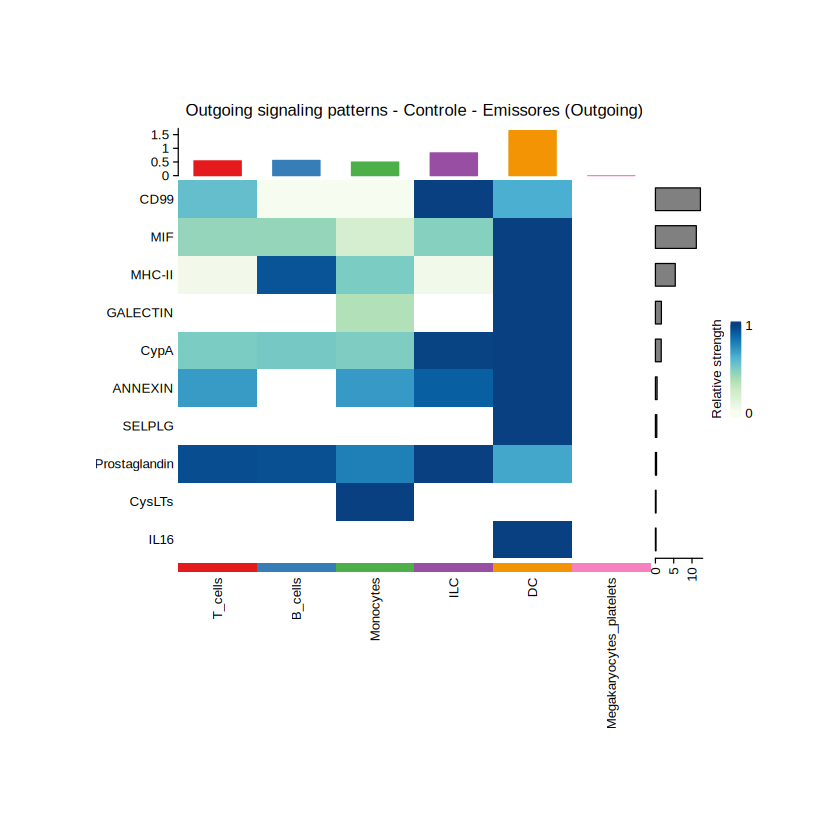

In [55]:
library(ComplexHeatmap)
cc_controle <- netAnalysis_computeCentrality(cc_controle, slot.name = "netP")
netAnalysis_signalingRole_heatmap(
  cc_controle, pattern = "outgoing",
  title = "Controle - Emissores (Outgoing)", color.heatmap = "GnBu"
)

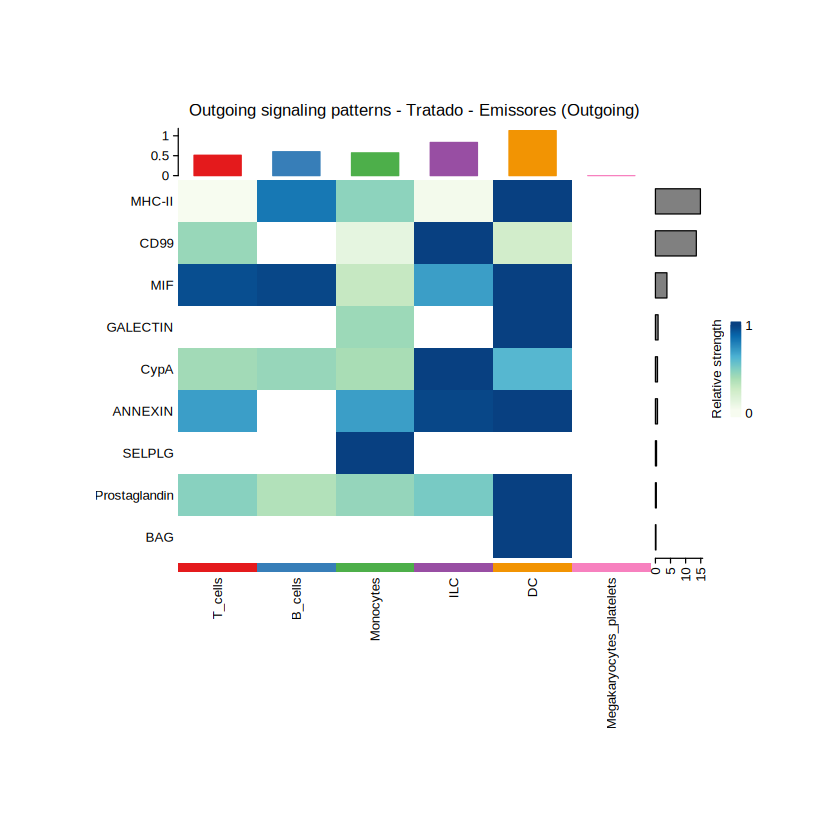

In [56]:
cc_tratado <- netAnalysis_computeCentrality(cc_tratado, slot.name = "netP")
netAnalysis_signalingRole_heatmap(
  cc_tratado, pattern = "outgoing",
  title = "Tratado - Emissores (Outgoing)", color.heatmap = "GnBu"
)

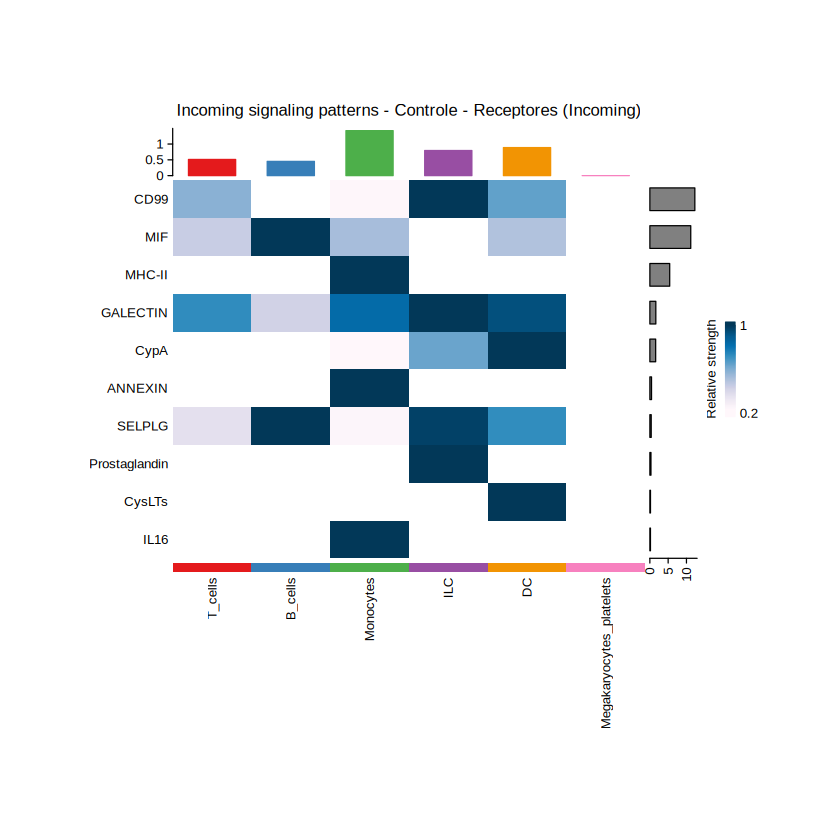

In [57]:
netAnalysis_signalingRole_heatmap(
  cc_controle, pattern = "incoming",
  title = "Controle - Receptores (Incoming)", color.heatmap = "PuBu"
)

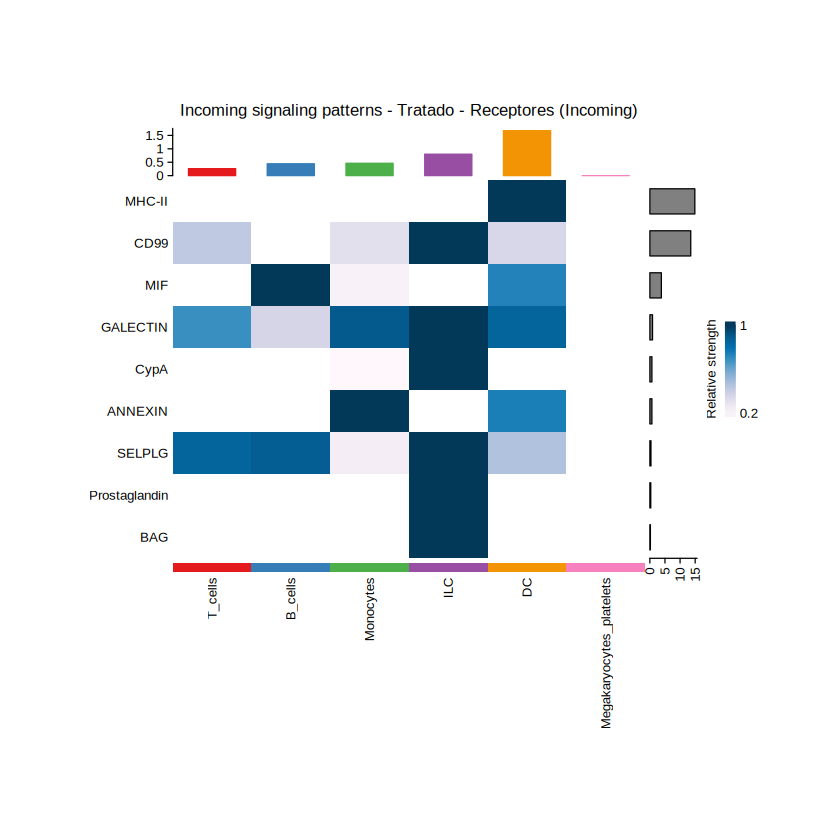

In [58]:
netAnalysis_signalingRole_heatmap(
  cc_tratado, pattern = "incoming",
  title = "Tratado - Receptores (Incoming)", color.heatmap = "PuBu"
)

---
### Foco em Alta Resolução: Diagrama de Cordas (Chord Diagram)

Às vezes, queremos dar um "zoom" na relação entre apenas dois tipos celulares. O **Chord Diagram** exibe interações genéticas específicas (Ligante no topo, Receptor embaixo) entre emissores e receptores selecionados.

* A espessura da "fita" que conecta o arco superior ao inferior representa a força de comunicação daquele par molecular específico (ex: *MIF -> CD74*).

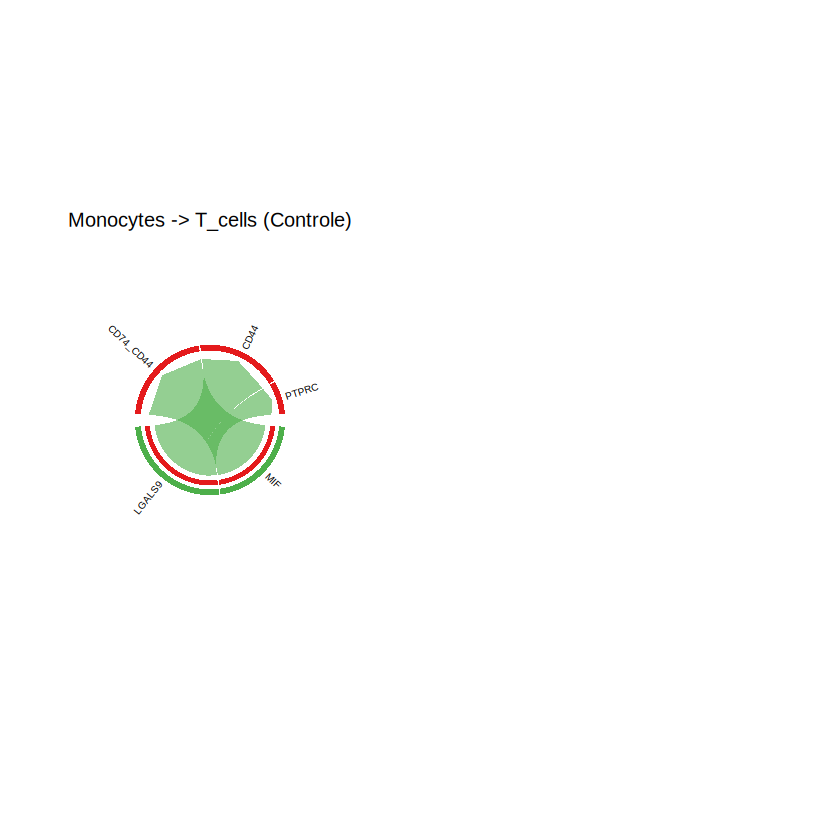

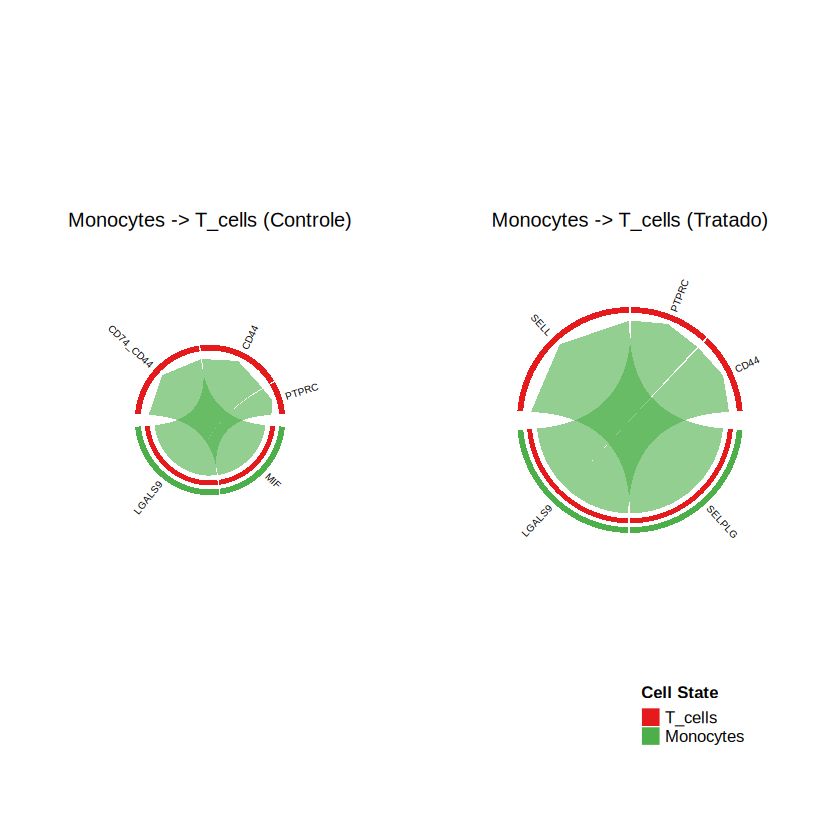

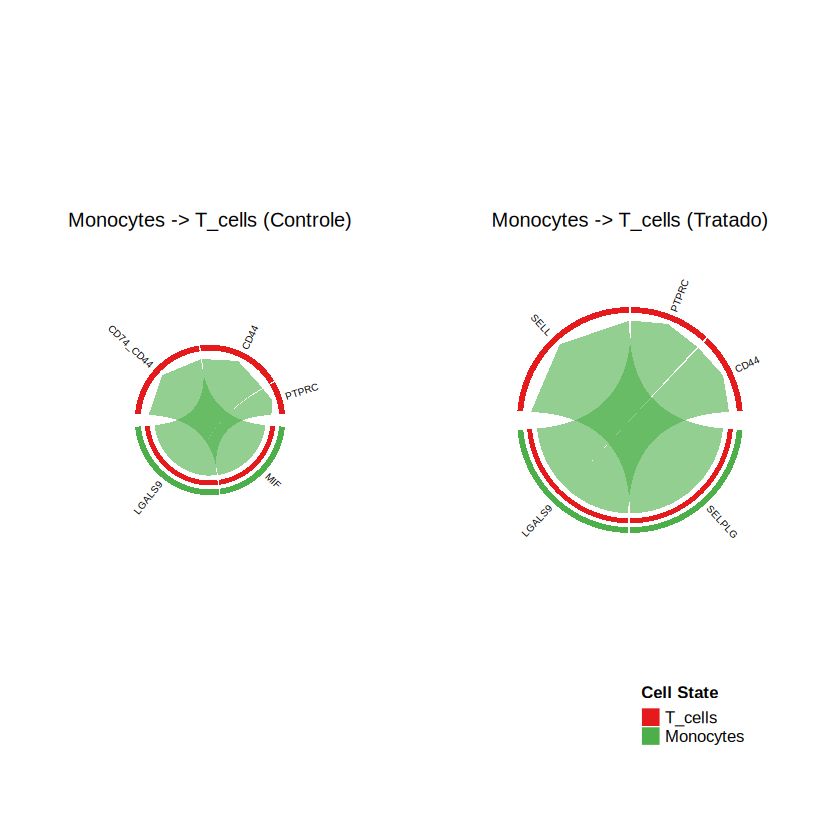

In [60]:
# 7. Diagrama de Cordas para um eixo de comunicação específico
# Ajustado com os nomes de populações padronizados (sem espaços ou barras)
par(mfrow = c(1,2), mar = c(0,0,0,0))

netVisual_chord_gene(
  cc_controle,
  sources.use = "Monocytes",
  targets.use = c("T_cells"),
  lab.cex = 0.5,
  title.name = "Monocytes -> T_cells (Controle)"
)

netVisual_chord_gene(
  cc_tratado,
  sources.use = "Monocytes",
  targets.use = c("T_cells"),
  lab.cex = 0.5,
  title.name = "Monocytes -> T_cells (Tratado)"
)

par(mfrow = c(1,1))

---
###  Wordcloud das Vias de Sinalização

O CellChat possui integração direta com o pacote `wordcloud` para resumir visualmente quais são as vias de sinalização mais ativas no microambiente tumoral.

* **Como funciona:** A função `netAnalysis_contribution` ou a extração direta das vias ordenadas permite alimentar a nuvem de palavras. Quanto maior e mais central for a palavra (ex: *MIF*, *CXCL*, *SPP1*), maior é a contribuição relativa daquela via para o volume total de comunicação do tecido.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: RColorBrewer



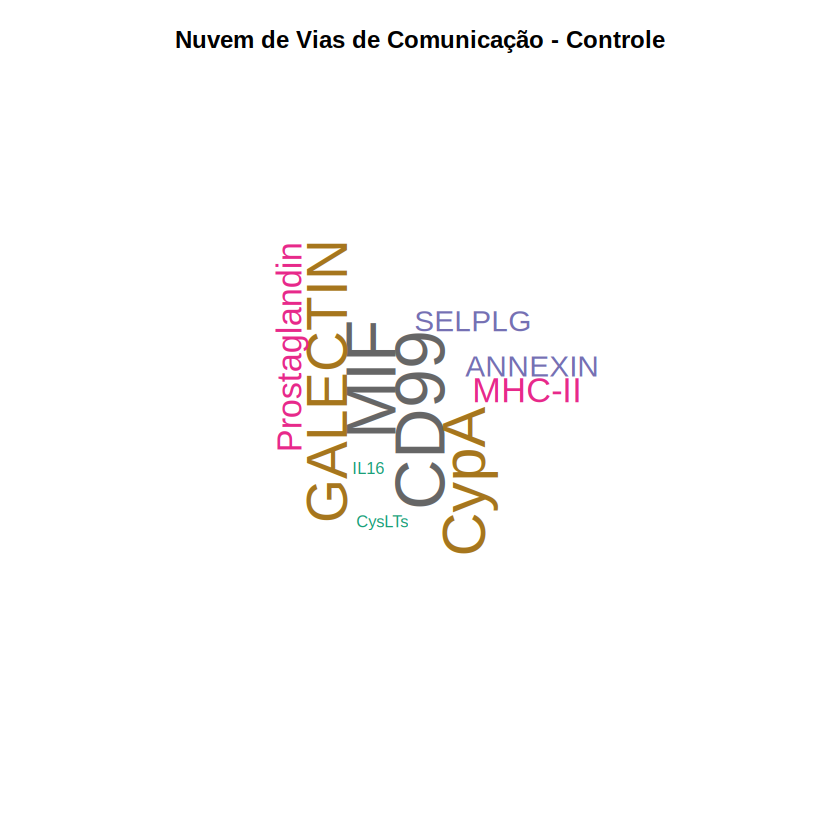

In [64]:
# BÔNUS: WORDCLOUD DE VIAS NO CELLCHAT (GRUPO CONTROLE)
install.packages("wordcloud")
library(wordcloud)
library(RColorBrewer)

# Extrai as interações do objeto cc_controle (mude para cc_tratado se quiser do outro grupo)
df_contrib <- subsetCommunication(cc_controle, slot.name = "netP")
pathway_freq <- sort(table(df_contrib$pathway_name), decreasing = TRUE)

# Gera a Nuvem de Palavras
par(mar = c(1, 1, 1, 1))
wordcloud(
  words = names(pathway_freq),
  freq = as.numeric(pathway_freq),
  scale = c(3.5, 0.6),
  min.freq = 1,
  max.words = 40,
  random.order = FALSE,
  rot.per = 0.25,
  colors = brewer.pal(8, "Dark2")
)
title("Nuvem de Vias de Comunicação - Controle", line = -1, cex.main = 1.2)

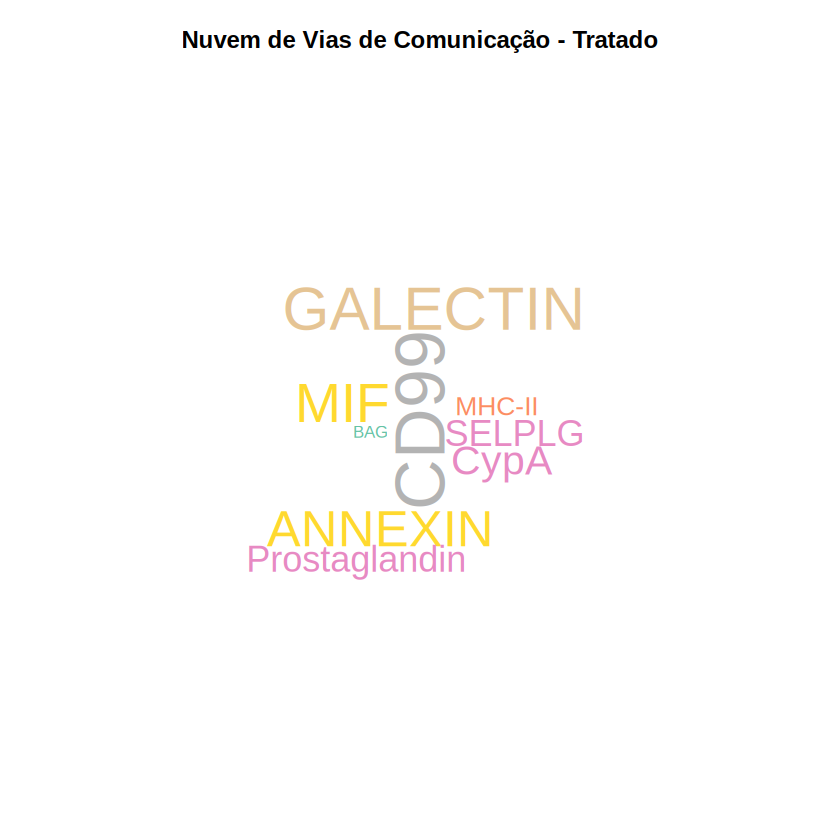

In [65]:
#Grupo tratado
# Extrai as interações do objeto cc_tratado
df_contrib_tratado <- subsetCommunication(cc_tratado, slot.name = "netP")
pathway_freq_tratado <- sort(table(df_contrib_tratado$pathway_name), decreasing = TRUE)

# Gera a Nuvem de Palavras para o grupo Tratado
par(mar = c(1, 1, 1, 1))
wordcloud(
  words = names(pathway_freq_tratado),
  freq = as.numeric(pathway_freq_tratado),
  scale = c(3.5, 0.6),
  min.freq = 1,
  max.words = 40,
  random.order = FALSE,
  rot.per = 0.25,
  colors = brewer.pal(8, "Set2") # paleta diferente (Set2) para destacar visualmente do Controle
)
title("Nuvem de Vias de Comunicação - Tratado", line = -1, cex.main = 1.2)

---
## Módulo 8: Trajetória Celular (Pseudotempo) com Slingshot

### O que é a Análise de Trajetória e para que serve?
Na biologia do câncer e do microambiente, as células não existem em estados estáticos e isolados. Elas passam por **transições dinâmicas** (por exemplo, monócitos circulantes que infiltram o tumor e se diferenciam em macrófagos associados ao tumor - TAMs, ou células em exaustão imunológica).

A análise de trajetória (**Pseudotempo**) visa ordenar as células ao longo de um eixo temporal computacional com base nas mudanças graduais de seus perfis de expressão gênica.

### Slingshot vs. Monocle 3: Qual escolher?

| Característica | Slingshot (Bioconductor) | Monocle 3 (Cole-Trapnell Lab) |
|---|---|---|
| **Abordagem Algorítmica** | Constrói curvas principais (*Principal Curves*) sobre o espaço reduzido (PCA/UMAP) utilizando os agrupamentos (clusters) já existentes. | Utiliza aprendizado de grafos topológicos (*Principal Graphs* / *SimplePPT*) para montar o esqueleto global. |
| **Complexidade Computacional** | **Baixa / Rápida.** Ideal para workshops e análises diretas de sub-populações. | **Alta / Mais Pesada.** Exige recomputar UMAPs próprios (`learn_graph`) e estruturar objetos específicos (`cell_data_set`). |
| **Integração com Seurat** | Perfeita via conversão simples para o objeto `SingleCellExperiment`. | Exige exportação de matrizes e metadados para construir a classe do Monocle do zero. |
| **Uso Recomendado** | Excelente para linhagens lineares ou bifurcações bem comportadas (ex: linhagem mieloide). | Ideal para topologias complexas com múltiplos ciclos, loops e redes altamente ramificadas. |

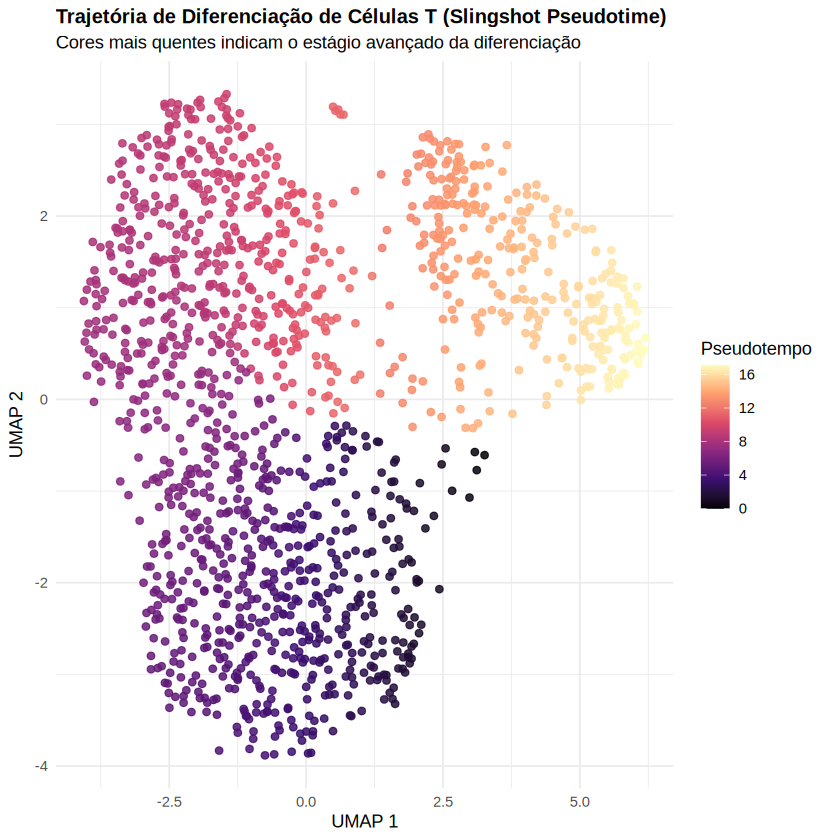

In [71]:
# MÓDULO 8: TRAJETÓRIA CELULAR NO COMPARTIMENTO DE CÉLULAS T (SLINGSHOT)

#BiocManager::install("DelayedMatrixStats")

library(DelayedMatrixStats)
library(Seurat)
library(slingshot)
library(SingleCellExperiment)
library(ggplot2)

# 1. Isolar apenas o compartimento de Células T usando o objeto 'pbmc'
cells_t <- colnames(pbmc)[Idents(pbmc) %in% c("T_cells", "CD4_T", "CD8_T", "T_reg")]
seurat_t <- subset(pbmc, cells = cells_t)

# 2. Re-executar reduções locais para o subset de Células T
seurat_t <- FindVariableFeatures(seurat_t, verbose = FALSE)
seurat_t <- RunPCA(seurat_t, npcs = 15, verbose = FALSE)
seurat_t <- RunUMAP(seurat_t, dims = 1:10, verbose = FALSE)
seurat_t <- FindNeighbors(seurat_t, dims = 1:10, verbose = FALSE)
seurat_t <- FindClusters(seurat_t, resolution = 0.4, verbose = FALSE)

# 3. Converter para o formato SingleCellExperiment exigido pelo Slingshot
sce_t <- as.SingleCellExperiment(seurat_t)

# 4. Executar o Slingshot informando os clusters e a redução UMAP (forçando o namespace do Slingshot)
sce_t <- slingshot::slingshot(sce_t, clusterLabels = "seurat_clusters", reducedDim = "UMAP")

# 5. Extrair o pseudotempo e as curvas chamando explicitamente a função do pacote
umap_coords <- SingleCellExperiment::reducedDim(sce_t, "UMAP")
pseudotempo_geral <- slingshot::slingPseudotime(sce_t)[, 1]

df_slingshot_t <- data.frame(
  UMAP_1 = umap_coords[, 1],
  UMAP_2 = umap_coords[, 2],
  Pseudotempo = pseudotempo_geral,
  Cluster = as.factor(SummarizedExperiment::colData(sce_t)$seurat_clusters)
)

# 6. Plotagem da Trajetória no UMAP para Células T
ggplot(df_slingshot_t, aes(x = UMAP_1, y = UMAP_2, color = Pseudotempo)) +
  geom_point(size = 1.8, alpha = 0.85) +
  scale_color_viridis_c(option = "magma", na.value = "grey85") +
  theme_minimal() +
  labs(
     title = "Trajetória de Diferenciação de Células T (Slingshot Pseudotime)",
     subtitle = "Cores mais quentes indicam o estágio avançado da diferenciação",
     color = "Pseudotempo",
     x = "UMAP 1",
     y = "UMAP 2"
  ) +
  theme(
     plot.title = element_text(face = "bold", size = 12),
     legend.position = "right"
  )

---
### O que o Gráfico de Trajetória do Slingshot demonstra e visualiza?

* **O Gradiente de Cores (Pseudotempo):** As células coloridas com tons escuros/roxos representam o início da linha evolutiva (raiz/células progenitoras ou infiltrantes iniciais). Conforme a célula se diferencia e avança no tempo biológico, a cor transiciona para tons laranjas e amarelos brilhantes (*endpoint* da trajetória).
* **A Conectividade Biológica:** Diferente de clusters isolados no UMAP, a curva principal calculada pelo Slingshot demonstra matematicamente se há uma transição suave de estados celulares, permitindo identificar quais fenótipos intermediários dão origem aos macrófagos polarizados no tumor.

---
## Módulo 9: Identificação de Células Tumorais Malignas via InferCNV

### O desafio de identificar células malignas por anotação automática
Ferramentas de Machine Learning como o *CellTypist* ou bases de referência baseadas em marcadores canônicos funcionam muito bem para mapear o microambiente normal (células T, B, endoteliais, fibroblastos).

No entanto, **elas frequentemente falham ou rotulam incorretamente as células tumorais**. Como o câncer é instável, mutado e heterogêneo, as células malignas derivadas do epitélio adquirem perfis aberrantes que não encaixam nas caixas dos modelos saudáveis, sendo chamadas genericamente de "Células Epiteliais".

### Como o InferCNV resolve esse problema?
O **InferCNV** (desenvolvido pelo Broad Institute) aborda a malignidade analisando a **Instabilidade Genômica (CNV - Copy Number Variation)**, que é uma marca registrada dos tumores sólidos (como o TNBC - *Triple-Negative Breast Cancer*).

1. **Seleção de Referência Saudável:** O algoritmo separa células do estroma e do sistema imune (como Linfócitos T e Macrófagos do mesmo paciente) que obrigatoriamente possuem um genoma normal diploide ($2n$) para servirem de linha de base de controle.
2. **Ordenação Cromossômica:** Os genes expressos na matriz de contagens são mapeados e ordenados sequencialmente ao longo de todos os cromossomos humanos (do Cromossomo 1 ao 22).
3. **Média em Janelas Móveis:** O programa calcula a expressão média em janelas de genes adjacentes para suavizar o ruído técnico inerente ao scRNA-seq.
4. **Subtração de Referência:** A expressão das células epiteliais/suspeitas é dividida pela média das células de referência saudáveis.
   * **Células Normais:** O resultado oscila em torno de 1 (linha neutra).
   * **Células Tumorais:** Apresentam desvios massivos ao longo de grandes regiões cromossômicas — **blocos vermelhos** indicam amplificações (ganhos de cópias gênicas) e **blocos azuis** indicam deleções (perdas de cópias).

> **Aplicações Práticas:** Com o mapa do InferCNV, o pesquisador consegue traçar um limite matemático exato entre as células epiteliais benignas do tecido mamário normal e as verdadeiras células clonais malignas do tumor, permitindo isolá-las para análises downstream de vias oncogênicas e crosstalk via CellChat.

In [ ]:
---
## Módulo 7: Salvando Resultados no Google Drive

```r
system("python3 -c 'from google.colab import drive; drive.mount(\"/content/drive\")'")
dir_saida <- "/content/drive/MyDrive/Curso_SingleCell_Cancer"
dir.create(dir_saida, showWarnings = FALSE, recursive = TRUE)

# Salva o objeto Seurat final ultra-enriquecido
saveRDS(pbmc, file = file.path(dir_saida, "pbmc_anotado_cellchat.rds"))